## Ćwiczenie 13: Wprowadzenie do analizy obrazów 3D i rekonstrukcji wielopłaszczyznowych (MPR - Multi-Planar Reconstruction)

### Cel zajęć
W dotychczasowych ćwiczeniach pracowaliśmy na pojedynczych przekrojach 2D. W praktyce radiologicznej badania tomografii komputerowej (TK) i rezonansu magnetycznego (MRI) mają postać **trójwymiarowych wolumenów** zapisanych jako seria dziesiątek lub setek dwuwymiarowych plików **DICOM**.

W tym notatniku krok po kroku zrealizujemy:
1. **Teorię wolumetrii medycznej:** pojęcie woksela, anizotropia przestrzenna, fizyczny układ współrzędnych pacjenta (**LPS**), płaszczyzny rekonstrukcji wielopłaszczyznowych (**MPR**) oraz projekcje **MIP / MinIP**.
2. **Korektę anizotropii wokseli (Resampling izotropowy):** porównanie przekrojów zniekształconych grubością warstwy z wolumenem przeskalowanym do siatki $1.0 \times 1.0 \times 1.0\;\text{mm}$.
3. **Nawigację w przestrzeni fizycznej (MPR z celownikiem) oraz projekcje naczyniowe MIP.**

---
### 1. Podstawy teoretyczne analizy danych 3D

#### A. Woksel i anizotropia przestrzenna
Podstawowym elementem obrazu 3D jest **woksel** (*volume element*) o fizycznych wymiarach $(\Delta x, \Delta y, \Delta z)$ wyrażonych w milimetrach:
* $\Delta x, \Delta y$ — rozdzielczość w płaszczyźnie akwizycji (*in-plane pixel spacing*, zazwyczaj $0.5\text{–}1.0\;\text{mm}$),
* $\Delta z$ — odległość między kolejnymi przekrojami / grubość warstwy (*slice thickness*, w badaniach przeglądowych często $2.5\text{–}5.0\;\text{mm}$).

Gdy $\Delta z \neq \Delta x$, wolumen jest **anizotropowy**. Bezpośrednie wyświetlenie macierzy pikseli wzdłuż osi $Z$ bez uwzględnienia wartości `Spacing` powoduje silne **spłaszczenie anatomii** (np. 4-krotne ściśnięcie kręgosłupa i nerek).

#### B. Indeksy macierzy vs. Przestrzeń fizyczna pacjenta (LPS)
Przy pracy z bibliotekami `SimpleITK` oraz `NumPy` należy pamiętać o odwrotnej kolejności osi:
* **`SimpleITK`:** kolejność `(X, Y, Z)` zgodna z geometrią fizyczną,
* **`NumPy` (`sitk.GetArrayFromImage`):** kolejność `(Z, Y, X)`, gdzie pierwszy indeks wybiera numer przekroju.

Przeliczenie indeksów woksela $(i, j, k)$ na fizyczne współrzędne pacjenta $\mathbf{p} = (x, y, z)\;[\text{mm}]$ w standardowym układzie **LPS** (*Left* — lewa strona pacjenta, *Posterior* — tył/plecy, *Superior* — góra/głowa) odbywa się według równania:
$$\mathbf{p} = \mathbf{o} + \mathbf{D} \cdot \begin{bmatrix} \Delta x & 0 & 0 \\ 0 & \Delta y & 0 \\ 0 & 0 & \Delta z \end{bmatrix} \begin{bmatrix} i \\ j \\ k \end{bmatrix}$$
gdzie $\mathbf{o}$ to `Origin` (położenie pierwszego woksela w mm), a $\mathbf{D}$ to macierz kierunków `Direction` ($3 \times 3$, zdefiniowana w nagłówku DICOM przez tag *Image Orientation Patient*).

#### C. Rekonstrukcje wielopłaszczyznowe (MPR — *Multi-Planar Reconstruction*)
MPR polega na wyznaczaniu dwuwymiarowych przekrojów w trzech wzajemnie prostopadłych płaszczyznach anatomicznych:
1. **Płaszczyzna osiowa / poprzeczna (*Axial / Transverse*):** przekrój dla ustalonej współrzędnej $z$ (tablica `vol[z, :, :]`) — dzieli ciało na część górną i dolną.
2. **Płaszczyzna czołowa (*Coronal*):** przekrój dla ustalonej współrzędnej $y$ (tablica `vol[:, y, :]`) — widok od przodu pacjenta (dzieli ciało na część przednią (brzuszną) i tylną (grzbietową).
3. **Płaszczyzna strzałkowa (*Sagittal*):** przekrój dla ustalonej współrzędnej $x$ (tablica `vol[:, :, x]`) — widok z boku pacjenta (dzieli ciało na stronę prawą i lewą).

#### D. Projekcje intensywności (MIP / MinIP)
Zamiast pojedynczego cienkiego plastra często analizuje się **grubą warstwę** (*slab*) o grubości kilkudziesięciu milimetrów, rzutując woksele wzdłuż wybranej osi:
* **MIP (*Maximum Intensity Projection*):** dla każdego promienia wybiera **maksymalną** wartość intensywności:
  $$\text{MIP}(x, z) = \max_{y \in [y_1, y_2]} I(x, y, z)$$
  Uwidacznia w jednym rzucie kręty przebieg naczyń krwionośnych wypełnionych kontrastem (angiografia TK) oraz struktury kostne.
* **MinIP (*Minimum Intensity Projection*):** wybiera **minimalną** wartość intensywności ($\min I$) — stosowane do oceny drzewa oskrzelowego oraz rozedmy płuc.

In [7]:
# Instalacja i import niezbędnych bibliotek
#!pip install -q SimpleITK scipy

import os
import shutil
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

print(f"Środowisko 3D gotowe (SimpleITK {sitk.__version__})")

Środowisko 3D gotowe (SimpleITK 2.5.7)


---
## 2. Wygenerowanie i wczytanie serii plików DICOM (`sitk.ImageSeriesReader`)

Aby notatnik działał niezależnie od zewnętrznych repozytoriów, poniższa funkcja generuje kompletne, zanonimizowane badanie TK jamy brzusznej w jednostkach Hounsfielda (**HU**) i zapisuje je na dysku jako **64 osobne pliki DICOM** w katalogu `badanie_tk_dicom/`:
* **Rozmiar macierzy:** $64 \times 192 \times 192$ wokseli,
* **Anizotropowy rozmiar woksela (`Spacing`):** $\Delta x = 0.75\;\text{mm}$, $\Delta y = 0.75\;\text{mm}$, $\Delta z = 3.50\;\text{mm}$ (współczynnik anizotropii $3.50 / 0.75 \approx 4.67$),
* **Struktury anatomiczne w skali HU:** powietrze ($-1000\;\text{HU}$), dolne partie płuc ($-760\;\text{HU}$), tkanka tłuszczowa ($-85\;\text{HU}$), miąższ wątroby i nerek ($+58\text{ do }+62\;\text{HU}$), ognisko hipodensyjne / torbiel w lewej nerce ($+12\;\text{HU}$), zakontrastowana aorta brzuszna wraz z tętnicami nerkowymi i biodrowymi ($+270\text{ do }+285\;\text{HU}$) oraz kręgosłup i żebra ($+720\text{ do }+850\;\text{HU}$).

In [16]:
def generate_sample_dicom_series(output_dir="badanie_tk_dicom"):
    """
    Generuje realistyczny, anizotropowy wolumen TK w jednostkach Hounsfielda (HU)
    i zapisuje go jako pełną serię plików DICOM (.dcm) z metadanymi przestrzennymi.
    """
    if os.path.exists(output_dir):
        shutil.rmtree(output_dir)
    os.makedirs(output_dir, exist_ok=True)

    Z, Y, X = 64, 192, 192
    spacing = (0.75, 0.75, 3.5)  # (dx, dy, dz) w mm
    origin = (-X * spacing[0] / 2.0, -Y * spacing[1] / 2.0, -Z * spacing[2] / 2.0)

    zz, yy, xx = np.mgrid[0:Z, 0:Y, 0:X].astype(np.float32)
    x_mm = origin[0] + xx * spacing[0]
    y_mm = origin[1] + yy * spacing[1]
    z_mm = origin[2] + zz * spacing[2]

    vol = np.full((Z, Y, X), -1000.0, dtype=np.float32)

    # Obrys tułowia oraz mięśnie jamy brzusznej
    waist = 1.0 - 0.06 * np.exp(-(z_mm / 45.0) ** 2)
    body_mask = ((x_mm / (64.0 * waist)) ** 2 + (y_mm / (46.0 * waist)) ** 2) <= 1.0
    inner_body = ((x_mm / (56.0 * waist)) ** 2 + (y_mm / (38.0 * waist)) ** 2) <= 1.0
    vol[body_mask] = -85.0
    vol[inner_body] = 42.0

    # Dolne partie płuc (górna część wolumenu)
    lung_r = (((x_mm + 26.0) / 20.0) ** 2 + ((y_mm + 2.0) / 22.0) ** 2 + ((z_mm - 108.0) / 48.0) ** 2) <= 1.0
    lung_l = (((x_mm - 26.0) / 20.0) ** 2 + ((y_mm + 2.0) / 22.0) ** 2 + ((z_mm - 108.0) / 48.0) ** 2) <= 1.0
    vol[(lung_r | lung_l) & inner_body] = -760.0

    # Wątroba i obie nerki + hipodensyjna torbiel w lewej nerce
    liver = (((x_mm + 24.0) / 28.0) ** 2 + ((y_mm + 4.0) / 24.0) ** 2 + ((z_mm - 32.0) / 26.0) ** 2) <= 1.0
    vol[liver & inner_body] = 62.0

    kidney_r = (((x_mm + 24.0) / 11.5) ** 2 + ((y_mm - 10.0) / 13.5) ** 2 + ((z_mm + 6.0) / 24.0) ** 2) <= 1.0
    kidney_l = (((x_mm - 24.0) / 11.5) ** 2 + ((y_mm - 10.0) / 13.5) ** 2 + ((z_mm + 2.0) / 24.0) ** 2) <= 1.0
    vol[kidney_r] = 58.0
    vol[kidney_l] = 58.0

    lesion = (((x_mm - 26.0) / 5.0) ** 2 + ((y_mm - 11.0) / 5.5) ** 2 + ((z_mm + 4.0) / 7.0) ** 2) <= 1.0
    vol[lesion] = 12.0

    # Kręgosłup (trzony kręgów, krążki międzykręgowe, kanał kręgowy, wyrostki) oraz żebra
    vertebra_body = ((x_mm / 10.5) ** 2 + ((y_mm - 19.0) / 9.5) ** 2) <= 1.0
    disc_gap = np.abs(((z_mm + 112.0) % 24.0) - 21.5) < 2.0
    vol[vertebra_body & (~disc_gap)] = 720.0
    vol[vertebra_body & disc_gap] = 65.0

    spinal_canal = ((x_mm / 4.2) ** 2 + ((y_mm - 28.5) / 4.0) ** 2) <= 1.0
    spinous_proc = ((x_mm / 3.0) ** 2 + ((y_mm - 34.0) / 5.0) ** 2) <= 1.0
    vol[spinous_proc & (~disc_gap)] = 680.0
    vol[spinal_canal] = 15.0

    for z_rib in [25.0, 52.0, 79.0]:
        rib_z_curve = z_rib - 0.35 * y_mm
        rib_ring = (
            (((x_mm / (57.0 * waist)) ** 2 + (y_mm / (39.0 * waist)) ** 2) <= 1.03)
            & (((x_mm / (57.0 * waist)) ** 2 + (y_mm / (39.0 * waist)) ** 2) >= 0.88)
            & (np.abs(z_mm - rib_z_curve) <= 3.2)
            & (y_mm > -28.0)
        )
        vol[rib_ring] = 850.0

    # Zakontrastowany układ naczyniowy (aorta, tętnice biodrowe i tętnice nerkowe)
    aorta_x = -3.0 + 1.5 * np.sin(z_mm / 40.0)
    aorta = (((x_mm - aorta_x) ** 2 + (y_mm - 6.0) ** 2) <= 3.8 ** 2) & (z_mm >= -48.0)
    vol[aorta] = 285.0

    t_iliac = np.clip((-48.0 - z_mm) / 64.0, 0.0, 1.0)
    iliac_r = (((x_mm - (-3.0 - 18.0 * t_iliac)) ** 2 + (y_mm - (6.0 - 8.0 * t_iliac)) ** 2) <= 2.7 ** 2) & (z_mm < -46.0)
    iliac_l = (((x_mm - (-3.0 + 21.0 * t_iliac)) ** 2 + (y_mm - (6.0 - 8.0 * t_iliac)) ** 2) <= 2.7 ** 2) & (z_mm < -46.0)
    vol[iliac_r | iliac_l] = 275.0

    t_ren_r = np.clip((-3.0 - x_mm) / 21.0, 0.0, 1.0)
    renal_art_r = (
        (((z_mm - (-5.0 - 3.0 * np.sin(t_ren_r * np.pi))) ** 2 + (y_mm - (6.0 + 4.0 * t_ren_r)) ** 2) <= 2.1 ** 2)
        & (x_mm <= -2.0) & (x_mm >= -24.0)
    )
    t_ren_l = np.clip((x_mm + 3.0) / 27.0, 0.0, 1.0)
    renal_art_l = (
        (((z_mm - (-2.0 + 3.5 * np.sin(t_ren_l * np.pi))) ** 2 + (y_mm - (6.0 + 4.0 * t_ren_l)) ** 2) <= 2.1 ** 2)
        & (x_mm >= -2.0) & (x_mm <= 24.0)
    )
    vol[renal_art_r | renal_art_l] = 270.0

    vol = gaussian_filter(vol, sigma=(0.4, 0.8, 0.8))
    rng = np.random.default_rng(42)
    vol += rng.normal(0.0, 10.0, size=vol.shape).astype(np.float32)
    vol_int16 = np.clip(vol, -1000.0, 1500.0).astype(np.int16)

    # Zapis kolejnych przekrojów 2D jako prawdziwa seria DICOM z nagłówkami przestrzennymi
    vol_sitk = sitk.GetImageFromArray(vol_int16)
    vol_sitk.SetSpacing(spacing)
    vol_sitk.SetOrigin(origin)

    writer = sitk.ImageFileWriter()
    writer.KeepOriginalImageUIDOn()
    for i in range(Z):
        slice_img = vol_sitk[:, :, i]
        slice_img.SetMetaData("0010|0010", "JAN^KOWALSKI_ANON")
        slice_img.SetMetaData("0010|0020", "CT-ABDOMEN-3D-01")
        slice_img.SetMetaData("0008|0060", "CT")
        slice_img.SetMetaData("0008|103e", "JAMA_BRZUSZNA_FAZA_TETNICZA")
        slice_img.SetMetaData("0020|000d", "1.2.826.0.1.3680043.8.498.10001")
        slice_img.SetMetaData("0020|000e", "1.2.826.0.1.3680043.8.498.20001")
        slice_img.SetMetaData("0008|0018", f"1.2.826.0.1.3680043.8.498.30001.{i + 1}")
        slice_img.SetMetaData("0020|0013", str(i + 1))
        slice_img.SetMetaData("0018|0050", str(spacing[2]))
        slice_img.SetMetaData("0018|0088", str(spacing[2]))
        slice_img.SetMetaData("0020|0037", "1\\0\\0\\0\\1\\0")
        slice_img.SetMetaData("0020|0032", f"{origin[0]}\\{origin[1]}\\{origin[2] + i * spacing[2]}")
        writer.SetFileName(os.path.join(output_dir, f"slice_{i:03d}.dcm"))
        writer.Execute(slice_img)

generate_sample_dicom_series("badanie_tk_dicom")

# -----------------------------------------------------------------
# WCZYTANIE SERII DICOM ZA POMOCĄ sitk.ImageSeriesReader
# -----------------------------------------------------------------
DICOM_DIR = "badanie_tk_dicom"
reader = sitk.ImageSeriesReader()
dicom_files = reader.GetGDCMSeriesFileNames(DICOM_DIR)
reader.SetFileNames(dicom_files)
reader.MetaDataDictionaryArrayUpdateOn()
reader.LoadPrivateTagsOn()

vol_3d = reader.Execute()

print(f"Liczba wczytanych plików DICOM : {len(dicom_files)}")
print(f"Pacjent (tag 0010|0010)        : {reader.GetMetaData(0, '0010|0010')}")
print(f"Modalność (tag 0008|0060)      : {reader.GetMetaData(0, '0008|0060')}")
print(f"Opis serii (tag 0008|103e)     : {reader.GetMetaData(0, '0008|103e')}")
print(f"Rozmiar wolumenu (X, Y, Z)     : {vol_3d.GetSize()} wokseli")
print(f"Rozmiar woksela Spacing (mm)   : {vol_3d.GetSpacing()}")
print(f"Punkt początkowy Origin (mm)   : {vol_3d.GetOrigin()}")
print(f"Macierz kierunków Direction    : {vol_3d.GetDirection()}")

Liczba wczytanych plików DICOM : 64
Pacjent (tag 0010|0010)        : JAN^KOWALSKI_ANON 
Modalność (tag 0008|0060)      : CT
Opis serii (tag 0008|103e)     : JAMA_BRZUSZNA_FAZA_TETNICZA 
Rozmiar wolumenu (X, Y, Z)     : (192, 192, 64) wokseli
Rozmiar woksela Spacing (mm)   : (0.75, 0.75, 3.5)
Punkt początkowy Origin (mm)   : (-72.0, -72.0, -112.0)
Macierz kierunków Direction    : (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0)


---
## 3. Problem anizotropii wokseli i resampling izotropowy (`sitk.Resample`)

W powyższym badaniu odległość między kolejnymi przekrojami wynosi $\Delta z = 3.5\;\text{mm}$, natomiast rozmiar piksela w płaszczyźnie osiowej to $\Delta x = \Delta y = 0.75\;\text{mm}$.

Aby uniknąć zniekształcenia proporcji na przekrojach **czołowych (Coronal)** i **strzałkowych (Sagittal)**, wykonujemy **resampling izotropowy** wolumenu do jednolitej rozdzielczości woksela $1.0 \times 1.0 \times 1.0\;\text{mm}$ z interpolacją liniową (`sitk.sitkLinear`).

Nowy rozmiar wolumenu izotropowego (X, Y, Z): (144, 144, 224) wokseli (1 woksel = 1.0 x 1.0 x 1.0 mm)


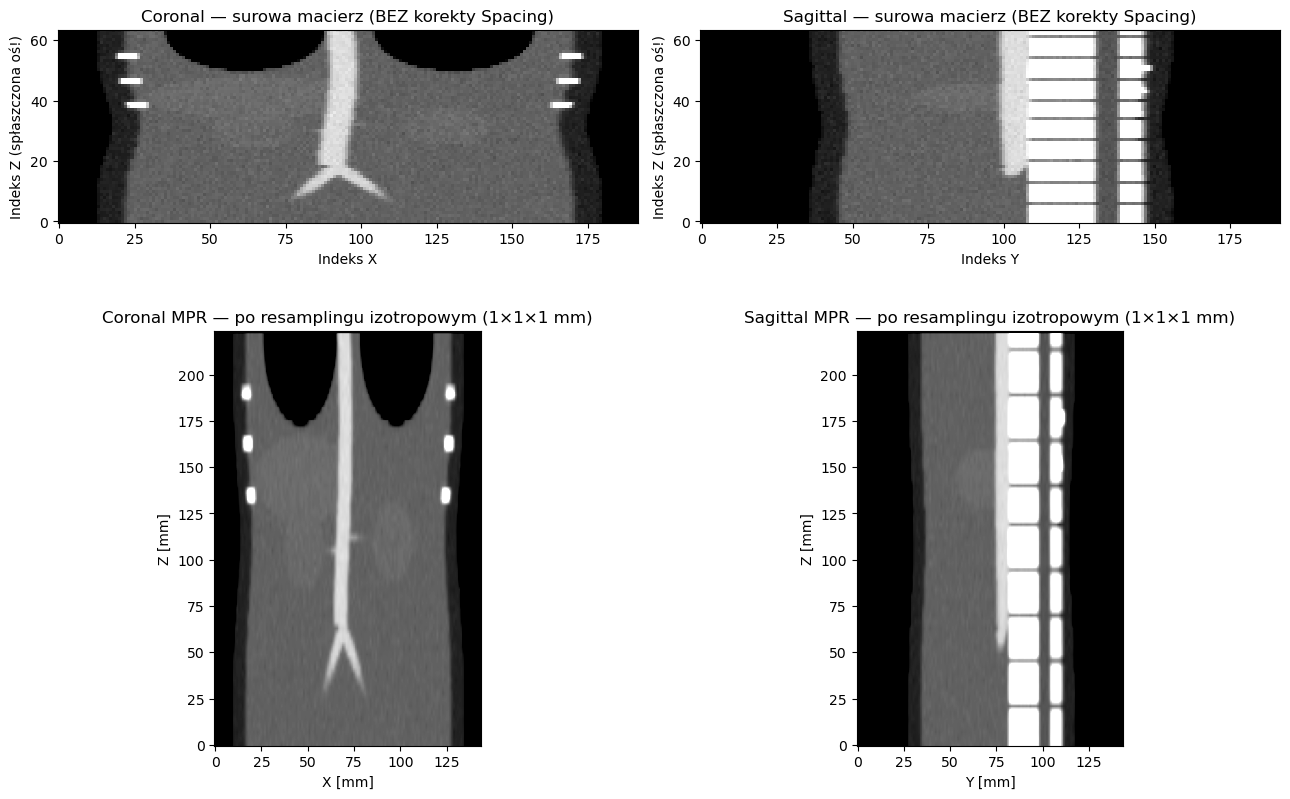

In [19]:
def resample_to_isotropic(image_3d, new_spacing=(1.0, 1.0, 1.0), interpolator=sitk.sitkLinear):
    """
    Przeskalowuje wolumen 3D SimpleITK do zadanej rozdzielczości izotropowej (w mm),
    zachowując jego fizyczne wymiary, Origin oraz macierz kierunków Direction.
    """
    orig_size = image_3d.GetSize()
    orig_spacing = image_3d.GetSpacing()

    new_size = [
        int(round(orig_size[i] * (orig_spacing[i] / new_spacing[i])))
        for i in range(3)
    ]

    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(new_spacing)
    resampler.SetSize(new_size)
    resampler.SetOutputDirection(image_3d.GetDirection())
    resampler.SetOutputOrigin(image_3d.GetOrigin())
    resampler.SetTransform(sitk.Transform())
    resampler.SetDefaultPixelValue(-1000)
    resampler.SetInterpolator(interpolator)

    return resampler.Execute(image_3d)

vol_iso = resample_to_isotropic(vol_3d, new_spacing=(1.0, 1.0, 1.0))
print(f"Nowy rozmiar wolumenu izotropowego (X, Y, Z): {vol_iso.GetSize()} wokseli (1 woksel = 1.0 x 1.0 x 1.0 mm)")

# Porównanie wizualne surowych przekrojów anizotropowych vs. wolumenu po resamplingu izotropowym
arr_raw = sitk.GetArrayFromImage(vol_3d)   # kształt (Z=64, Y=192, X=192)
arr_iso = sitk.GetArrayFromImage(vol_iso)  # kształt (Z=224, Y=144, X=144)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# Górny wiersz: surowa macierz NumPy bez uwzględnienia Spacing (4.67x spłaszczenie)
ax[0, 0].imshow(arr_raw[:, 102, :], cmap='gray', vmin=-150, vmax=350, origin='lower')
ax[0, 0].set_title("Coronal — surowa macierz (BEZ korekty Spacing)")
ax[0, 0].set_xlabel("Indeks X")
ax[0, 0].set_ylabel("Indeks Z (spłaszczona oś!)")

ax[0, 1].imshow(arr_raw[:, :, 93], cmap='gray', vmin=-150, vmax=350, origin='lower')
ax[0, 1].set_title("Sagittal — surowa macierz (BEZ korekty Spacing)")
ax[0, 1].set_xlabel("Indeks Y")
ax[0, 1].set_ylabel("Indeks Z (spłaszczona oś!)")

# Dolny wiersz: wolumen po resamplingu izotropowym 1 x 1 x 1 mm
ax[1, 0].imshow(arr_iso[:, 77, :], cmap='gray', vmin=-150, vmax=350, origin='lower')
ax[1, 0].set_title("Coronal MPR — po resamplingu izotropowym (1×1×1 mm)")
ax[1, 0].set_xlabel("X [mm]")
ax[1, 0].set_ylabel("Z [mm]")

ax[1, 1].imshow(arr_iso[:, :, 70], cmap='gray', vmin=-150, vmax=350, origin='lower')
ax[1, 1].set_title("Sagittal MPR — po resamplingu izotropowym (1×1×1 mm)")
ax[1, 1].set_xlabel("Y [mm]")
ax[1, 1].set_ylabel("Z [mm]")

plt.tight_layout()
plt.show()

---
## 4. Nawigacja w przestrzeni fizycznej: widok MPR z celownikiem (*Crosshair*)

W stacjach opisowych PACS lekarz "klika" konkretny punkt anatomiczny w przestrzeni 3D (wyrażony w milimetrach), a oprogramowanie automatycznie synchronizuje wszystkie trzy ortogonalne przekroje (*Axial*, *Coronal*, *Sagittal*).

Wykorzystamy metodę `vol_iso.TransformPhysicalPointToIndex((x_mm, y_mm, z_mm))`, aby ustawić celownik dokładnie w środku ogniska hipodensyjnego w lewej nerce (`x = +26.0 mm, y = +11.0 mm, z = -4.0 mm`).

Punkt fizyczny (26.0, 11.0, -4.0) mm -> indeksy woksela (X=98, Y=83, Z=108)


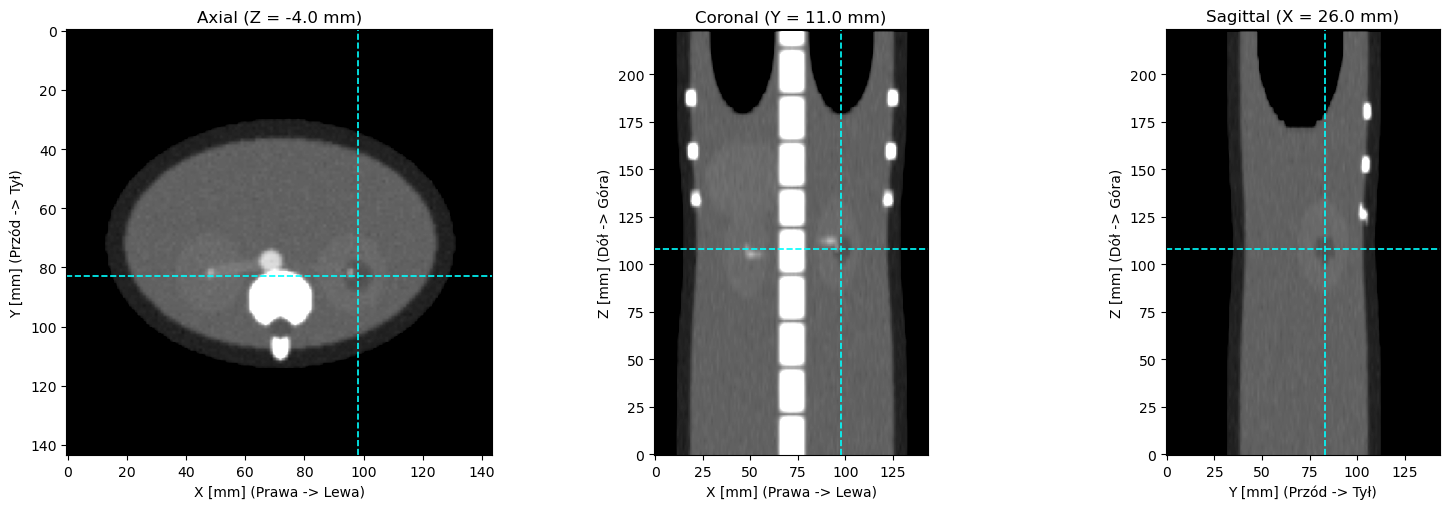

In [26]:
# Współrzędne fizyczne (w mm) ogniska w lewej nerce
target_point_mm = (26.0, 11.0, -4.0)

# Konwersja współrzędnych fizycznych (X, Y, Z) -> indeksy woksela (ix, iy, iz)
ix, iy, iz = vol_iso.TransformPhysicalPointToIndex(target_point_mm)
print(f"Punkt fizyczny {target_point_mm} mm -> indeksy woksela (X={ix}, Y={iy}, Z={iz})")

fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))

# 1. Przekrój osiowy (Axial: stałe Z)
ax[0].imshow(arr_iso[iz, :, :], cmap='gray', vmin=-150, vmax=350)
ax[0].axvline(ix, color='cyan', linestyle='--', linewidth=1.2)
ax[0].axhline(iy, color='cyan', linestyle='--', linewidth=1.2)
ax[0].set_title(f"Axial (Z = {target_point_mm[2]:.1f} mm)")
ax[0].set_xlabel("X [mm] (Prawa -> Lewa)")
ax[0].set_ylabel("Y [mm] (Przód -> Tył)")

# 2. Przekrój czołowy (Coronal: stałe Y)
ax[1].imshow(arr_iso[:, iy, :], cmap='gray', vmin=-150, vmax=350, origin='lower')
ax[1].axvline(ix, color='cyan', linestyle='--', linewidth=1.2)
ax[1].axhline(iz, color='cyan', linestyle='--', linewidth=1.2)
ax[1].set_title(f"Coronal (Y = {target_point_mm[1]:.1f} mm)")
ax[1].set_xlabel("X [mm] (Prawa -> Lewa)")
ax[1].set_ylabel("Z [mm] (Dół -> Góra)")

# 3. Przekrój strzałkowy (Sagittal: stałe X)
ax[2].imshow(arr_iso[:, :, ix], cmap='gray', vmin=-150, vmax=350, origin='lower')
ax[2].axvline(iy, color='cyan', linestyle='--', linewidth=1.2)
ax[2].axhline(iz, color='cyan', linestyle='--', linewidth=1.2)
ax[2].set_title(f"Sagittal (X = {target_point_mm[0]:.1f} mm)")
ax[2].set_xlabel("Y [mm] (Przód -> Tył)")
ax[2].set_ylabel("Z [mm] (Dół -> Góra)")

plt.tight_layout()
plt.show()

---
## 5. Projekcje maksymalnej intensywności (MIP) oraz okienkowanie TK

Pojedynczy przekrój czołowy o grubości $1\;\text{mm}$ nie jest w stanie uchwycić jednocześnie całej aorty brzusznej, obu tętnic nerkowych oraz rozwidlenia biodrowego, ponieważ naczynia te biegną w różnych głębokościach osi $Y$.

Obliczając **projekcję maksymalnej intensywności (`np.max`)** wzdłuż warstwy obejmującej przestrzeń zaotrzewnową (`Y` od `55` do `95` mm), uzyskujemy obraz angiograficzny 2D pokazujący pełną ciągłość drzewa naczyniowego na tle kośćca.

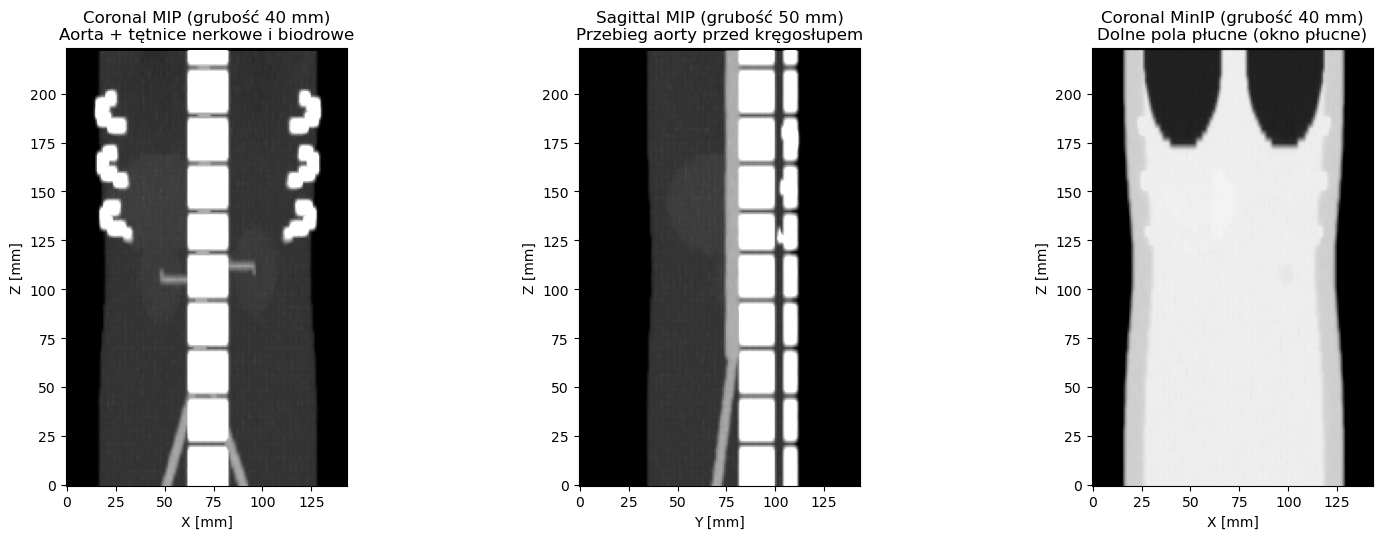

In [29]:
# Projekcja MIP w płaszczyźnie czołowej (Coronal MIP dla warstwy Y = 55..95 mm)
coronal_mip = np.max(arr_iso[:, 55:95, :], axis=1)

# Projekcja MIP w płaszczyźnie strzałkowej (Sagittal MIP dla warstwy X = 45..95 mm)
sagittal_mip = np.max(arr_iso[:, :, 45:95], axis=2)

# Projekcja minimalnej intensywności (Coronal MinIP) — uwidacznia powietrzne partie płuc
coronal_minip = np.min(arr_iso[:, 55:95, :], axis=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))

ax[0].imshow(coronal_mip, cmap='gray', vmin=-50, vmax=450, origin='lower')
ax[0].set_title("Coronal MIP (grubość 40 mm)\nAorta + tętnice nerkowe i biodrowe")
ax[0].set_xlabel("X [mm]")
ax[0].set_ylabel("Z [mm]")

ax[1].imshow(sagittal_mip, cmap='gray', vmin=-50, vmax=450, origin='lower')
ax[1].set_title("Sagittal MIP (grubość 50 mm)\nPrzebieg aorty przed kręgosłupem")
ax[1].set_xlabel("Y [mm]")
ax[1].set_ylabel("Z [mm]")

ax[2].imshow(coronal_minip, cmap='gray', vmin=-900, vmax=100, origin='lower')
ax[2].set_title("Coronal MinIP (grubość 40 mm)\nDolne pola płucne (okno płucne)")
ax[2].set_xlabel("X [mm]")
ax[2].set_ylabel("Z [mm]")

plt.tight_layout()
plt.show()